# WLASL-100 MediaPipe landmark extraction

This notebook converts the valid, preprocessed WLASL-100 RGB frame sequences into temporal pose and hand landmark tensors. It performs extraction and quality assessment only: it does not change frozen signer-independent partitions, engineer learned features, or train a recognition model.

## 1. Research context

Only instances marked usable by Notebook 03 are eligible. Missing acquisitions stay absent; a missing hand or pose detection is represented by `NaN` coordinates and an explicit Boolean detection mask, never silently as a real zero coordinate. Each output preserves 32 time steps for classical temporal features and recurrent models.

## 2. Input data and project configuration

Root discovery is independent of the current Jupyter directory. Default settings process every usable manifest row in deterministic video-ID order. Enable `DEBUG_MODE` only for a short smoke run; it does not alter frozen metadata.

In [78]:
from pathlib import Path
import json, os, tempfile, time
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

PROJECT_DIR = None  # optionally set to the repository root
DEBUG_MODE = False
DEBUG_MAX_INSTANCES = 3
FORCE_RECOMPUTE = False
TARGET_FRAMES = 32
FRAME_SHAPE = (256, 256, 3)
POSE_MODEL_COMPLEXITY = 1
MIN_DETECTION_CONFIDENCE = 0.5
MIN_TRACKING_CONFIDENCE = 0.5
LOW_DETECTION_RATE = 0.10

def find_project_root(override=None):
    marker = Path('WLASL/start_kit/WLASL_v0.3.json')
    candidates = ([Path(override).expanduser()] if override else []) + [Path.home() / 'sign-language-recognition']
    here = Path.cwd().resolve(); candidates += [here, *here.parents]
    for root in candidates:
        if (root.resolve() / marker).is_file(): return root.resolve()
    raise FileNotFoundError('Set PROJECT_DIR to a directory containing WLASL/start_kit/WLASL_v0.3.json.')

PROJECT_ROOT = find_project_root(PROJECT_DIR)
DATA_DIR = PROJECT_ROOT / 'data/processed/WLASL100'
FRAMES_DIR = DATA_DIR / 'frames'
LANDMARKS_DIR = DATA_DIR / 'landmarks'
QC_DIR = LANDMARKS_DIR / 'quality_control'
PREPROCESSING_MANIFEST = DATA_DIR / 'preprocessing_manifest.csv'
METADATA_PATHS = {s: DATA_DIR / f'{s}_metadata.csv' for s in ('train', 'val', 'test')}
LANDMARK_MANIFEST = LANDMARKS_DIR / 'landmark_manifest.csv'
ERRORS_PATH = LANDMARKS_DIR / 'landmark_extraction_errors.csv'
SUMMARY_PATH = LANDMARKS_DIR / 'landmark_extraction_summary.json'
LANDMARKS_DIR.mkdir(parents=True, exist_ok=True); QC_DIR.mkdir(parents=True, exist_ok=True)
print(f'Project root: {PROJECT_ROOT}\nInput frames: {FRAMES_DIR}\nLandmark output: {LANDMARKS_DIR}\nMediaPipe: {mp.__version__}')

Project root: /Users/sahilchauhan/sign-language-recognition
Input frames: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/frames
Landmark output: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/landmarks
MediaPipe: 0.10.21


## 3. Environment and MediaPipe initialization

MediaPipe Pose provides 33 normalized image-space landmarks `(x, y, z, visibility)`; Hands provides 21 normalized image-space landmarks `(x, y, z)` per detected hand. `x` grows rightward and `y` downward in the 256×256 RGB frame. `z` is MediaPipe's relative depth estimate, not an anatomically normalized metric. Notebook 03 applies no horizontal mirroring. MediaPipe Hands interprets labels under a mirrored-selfie assumption, so raw `Left`/`Right` labels are swapped when stored: `left_hand` and `right_hand` denote the subject’s anatomical sides for the unmirrored WLASL frame. The raw labels are recorded only in the visual diagnostic, not treated as anatomical ground truth.

In [79]:
def make_solutions():
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=POSE_MODEL_COMPLEXITY,
        enable_segmentation=False, smooth_landmarks=True, min_detection_confidence=MIN_DETECTION_CONFIDENCE,
        min_tracking_confidence=MIN_TRACKING_CONFIDENCE)
    hands = mp.solutions.hands.Hands(static_image_mode=False, max_num_hands=2, model_complexity=1,
        min_detection_confidence=MIN_DETECTION_CONFIDENCE, min_tracking_confidence=MIN_TRACKING_CONFIDENCE)
    return pose, hands

EXTRACTION_CONFIG = {'target_frames': TARGET_FRAMES, 'frame_shape_hwc': list(FRAME_SHAPE), 'input_color_order': 'RGB',
    'pose_model_complexity': POSE_MODEL_COMPLEXITY, 'min_detection_confidence': MIN_DETECTION_CONFIDENCE,
    'min_tracking_confidence': MIN_TRACKING_CONFIDENCE, 'mediapipe_version': mp.__version__,
    'missing_representation': 'NaN coordinates plus Boolean per-frame detection mask', 'handedness_convention': 'subject anatomical left/right; swapped from raw MediaPipe selfie labels for unmirrored frames'}
print(json.dumps(EXTRACTION_CONFIG, indent=2))

{
  "target_frames": 32,
  "frame_shape_hwc": [
    256,
    256,
    3
  ],
  "input_color_order": "RGB",
  "pose_model_complexity": 1,
  "min_detection_confidence": 0.5,
  "min_tracking_confidence": 0.5,
  "mediapipe_version": "0.10.21",
  "missing_representation": "NaN coordinates plus Boolean per-frame detection mask",
  "handedness_convention": "subject anatomical left/right; swapped from raw MediaPipe selfie labels for unmirrored frames"
}


Anatomical left/right labels are inferred by swapping MediaPipe's handedness classifications for unmirrored input frames. This convention is supported by the preprocessing pipeline and diagnostic inspection, but has not been independently verified for every source video.

## 4. Load and validate preprocessing manifest

The preprocessing manifest, rather than a directory listing alone, is the eligibility record. It is joined to the frozen CSVs and checked for split and signer consistency before extraction.

In [80]:
def read_metadata():
    tables = []
    for split, path in METADATA_PATHS.items():
        if not path.is_file(): raise FileNotFoundError(f'Missing frozen metadata: {path}')
        table = pd.read_csv(path, dtype={'video_id': str, 'signer_id': str})
        required = {'video_id', 'gloss', 'signer_id'}
        if required - set(table.columns): raise ValueError(f'{path.name} lacks {sorted(required-set(table.columns))}')
        table['video_id'] = table.video_id.str.strip(); table['signer_id'] = table.signer_id.astype(str).str.strip()
        table['experimental_split'] = split; tables.append(table)
    frozen = pd.concat(tables, ignore_index=True)
    if frozen.video_id.duplicated().any(): raise ValueError('Duplicate video IDs found across frozen splits')
    for a in METADATA_PATHS:
        for b in METADATA_PATHS:
            if a < b:
                overlap = set(frozen.loc[frozen.experimental_split.eq(a), 'signer_id']) & set(frozen.loc[frozen.experimental_split.eq(b), 'signer_id'])
                if overlap: raise ValueError(f'Signer overlap between {a} and {b}: {sorted(overlap)[:5]}')
    return frozen

if not PREPROCESSING_MANIFEST.is_file(): raise FileNotFoundError(f'Notebook 03 manifest missing: {PREPROCESSING_MANIFEST}')
frozen = read_metadata()
pre_manifest = pd.read_csv(PREPROCESSING_MANIFEST, dtype={'video_id': str, 'signer_id': str})
required_manifest = {'video_id', 'gloss', 'signer_id', 'experimental_split', 'output_path', 'usable'}
if required_manifest - set(pre_manifest.columns): raise ValueError(f'Preprocessing manifest lacks {sorted(required_manifest-set(pre_manifest.columns))}')
pre_manifest['video_id'] = pre_manifest.video_id.str.strip(); pre_manifest['signer_id'] = pre_manifest.signer_id.astype(str).str.strip()
eligible = pre_manifest.loc[pre_manifest.usable.fillna(False).astype(bool)].copy()
check = eligible.merge(frozen[['video_id','gloss','signer_id','experimental_split']], on='video_id', suffixes=('_manifest','_frozen'), how='left', validate='one_to_one')
for field in ('gloss','signer_id','experimental_split'):
    if check[f'{field}_frozen'].isna().any() or not (check[f'{field}_manifest'] == check[f'{field}_frozen']).all():
        raise ValueError(f'Frozen assignment mismatch in {field}')
eligible = eligible.sort_values('video_id', kind='stable').reset_index(drop=True)
print(f'Metadata rows: {len(frozen):,}; usable preprocessed sequences: {len(eligible):,}')
display(eligible.groupby('experimental_split').size().rename('eligible_sequences').to_frame())

Metadata rows: 2,038; usable preprocessed sequences: 457


,eligible_sequences
experimental_split,
test,244
train,182
val,31


## 5. Landmark extraction functions

Each `.npz` stores `pose (32,33,4)`, `left_hand/right_hand (32,21,3)`, Boolean masks `(32,)`, and handedness scores `(32,)`. Hand confidence is the MediaPipe handedness classification score; MediaPipe Hands does not expose a landmark-level confidence. All missing coordinate slots remain `NaN`.

In [81]:
def load_frames(path):
    with np.load(path) as bundle: frames = bundle['frames']
    if frames.shape != (TARGET_FRAMES, *FRAME_SHAPE): raise ValueError(f'Unexpected frame shape {frames.shape}')
    if frames.dtype != np.uint8: raise ValueError(f'Expected uint8 frames, got {frames.dtype}')
    return frames

def empty_landmarks():
    return (np.full((TARGET_FRAMES, 33, 4), np.nan, np.float32), np.full((TARGET_FRAMES, 21, 3), np.nan, np.float32),
            np.full((TARGET_FRAMES, 21, 3), np.nan, np.float32), np.zeros(TARGET_FRAMES, bool), np.zeros(TARGET_FRAMES, bool),
            np.zeros(TARGET_FRAMES, bool), np.full(TARGET_FRAMES, np.nan, np.float32), np.full(TARGET_FRAMES, np.nan, np.float32))

def extract_sequence(frames, pose, hands):
    pose_array, left, right, pose_mask, left_mask, right_mask, left_score, right_score = empty_landmarks()
    for t, frame in enumerate(frames):
        frame.flags.writeable = False
        pose_result, hand_result = pose.process(frame), hands.process(frame)
        frame.flags.writeable = True
        if pose_result.pose_landmarks:
            pose_array[t] = [[p.x, p.y, p.z, p.visibility] for p in pose_result.pose_landmarks.landmark]
            pose_mask[t] = True
        if hand_result.multi_hand_landmarks:
            labels = hand_result.multi_handedness or []
            for landmarks, handedness in zip(hand_result.multi_hand_landmarks, labels):
                category = handedness.classification[0]
                # MediaPipe labels assume mirrored selfie input; WLASL RGB frames are not mirrored.
                target, mask, score = (right, right_mask, right_score) if category.label == 'Left' else (left, left_mask, left_score)
                if not mask[t] or category.score > score[t]:
                    target[t] = [[p.x, p.y, p.z] for p in landmarks.landmark]
                    mask[t], score[t] = True, category.score
    return {'pose': pose_array, 'left_hand': left, 'right_hand': right, 'pose_detected': pose_mask,
            'left_hand_detected': left_mask, 'right_hand_detected': right_mask,
            'left_handedness_score': left_score, 'right_handedness_score': right_score}

def output_valid(path, video_id):
    try:
        with np.load(path, allow_pickle=False) as z:
            return (str(z['video_id'].item()) == str(video_id) and z['pose'].shape == (TARGET_FRAMES,33,4)
                    and z['left_hand'].shape == (TARGET_FRAMES,21,3) and z['right_hand'].shape == (TARGET_FRAMES,21,3)
                    and all(z[k].shape == (TARGET_FRAMES,) for k in ('pose_detected','left_hand_detected','right_hand_detected')))
    except Exception: return False

def atomic_save(path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix='.npz', delete=False) as f: temporary = Path(f.name)
    try:
        np.savez_compressed(temporary, **payload); os.replace(temporary, path)
    finally:
        if temporary.exists(): temporary.unlink()

def rates(payload):
    return {f'{name}_frames': int(payload[name].sum()) for name in ('pose_detected','left_hand_detected','right_hand_detected')} | {f'{name}_rate': float(payload[name].mean()) for name in ('pose_detected','left_hand_detected','right_hand_detected')}

## 6. Debug extraction on a few instances

This optional, non-writing smoke test verifies MediaPipe and the input contract before the full loop. It runs only when `DEBUG_MODE=True`.

In [82]:
if DEBUG_MODE and not eligible.empty:
    pose, hands = make_solutions()
    try:
        for row in eligible.head(DEBUG_MAX_INSTANCES).itertuples(index=False):
            result = extract_sequence(load_frames(row.output_path), pose, hands)
            print(row.video_id, rates(result))
    finally:
        pose.close(); hands.close()
elif DEBUG_MODE:
    print('No eligible sequences for debug extraction.')
else:
    print('DEBUG_MODE is False; full extraction will process all eligible sequences.')

DEBUG_MODE is False; full extraction will process all eligible sequences.


## 7. Full landmark extraction

Inputs are processed one at a time. Valid existing outputs are reopened and reused unless `FORCE_RECOMPUTE=True`; failures are recorded, not silently skipped. The Pose and Hands resources are explicitly closed at completion.

In [83]:
work = eligible.head(DEBUG_MAX_INSTANCES).copy() if DEBUG_MODE else eligible.copy()
records, errors = [], []
pose = hands = None
try:
    pose, hands = make_solutions()
    for row in tqdm(work.itertuples(index=False), total=len(work), desc='Extracting landmarks'):
        destination = LANDMARKS_DIR / f'{row.video_id}.npz'
        base = {'video_id': row.video_id, 'gloss': row.gloss, 'signer_id': str(row.signer_id), 'experimental_split': row.experimental_split,
                'input_path': row.output_path, 'landmark_path': str(destination), 'frame_count': TARGET_FRAMES}
        try:
            if destination.exists() and not FORCE_RECOMPUTE and output_valid(destination, row.video_id):
                with np.load(destination, allow_pickle=False) as z: payload = {k: z[k] for k in z.files}
                status = 'skipped_existing_valid'
            else:
                frames = load_frames(row.output_path)
                payload = extract_sequence(frames, pose, hands)
                payload |= {'video_id': np.array(str(row.video_id)), 'gloss': np.array(str(row.gloss)), 'signer_id': np.array(str(row.signer_id)),
                            'experimental_split': np.array(str(row.experimental_split)), 'frame_count': np.array(TARGET_FRAMES, np.int16),
                            'extraction_config_json': np.array(json.dumps(EXTRACTION_CONFIG, sort_keys=True))}
                atomic_save(destination, payload); status = 'processed'
            record = base | {'status': status, 'error_reason': '', **rates(payload)}
            record['low_detection_quality'] = bool(record['pose_detected_rate'] < LOW_DETECTION_RATE and record['left_hand_detected_rate'] < LOW_DETECTION_RATE and record['right_hand_detected_rate'] < LOW_DETECTION_RATE)
            records.append(record)
        except Exception as exc:
            message = f'{type(exc).__name__}: {exc}'
            records.append(base | {'status': 'failed', 'error_reason': message, 'pose_detected_frames': 0, 'left_hand_detected_frames': 0, 'right_hand_detected_frames': 0, 'pose_detected_rate': np.nan, 'left_hand_detected_rate': np.nan, 'right_hand_detected_rate': np.nan, 'low_detection_quality': False})
            errors.append(base | {'error_type': type(exc).__name__, 'error_message': str(exc)})
finally:
    if pose is not None: pose.close()
    if hands is not None: hands.close()

manifest = pd.DataFrame(records)
error_columns = ['video_id','gloss','signer_id','experimental_split','input_path','landmark_path','frame_count','error_type','error_message']
pd.DataFrame(errors, columns=error_columns).to_csv(ERRORS_PATH, index=False)
manifest.to_csv(LANDMARK_MANIFEST, index=False)
print(f'Wrote {LANDMARK_MANIFEST}\nWrote {ERRORS_PATH}')
display(manifest.groupby(['experimental_split','status']).size().unstack(fill_value=0) if not manifest.empty else pd.DataFrame())

I0000 00:00:1793787197.918929 1086912 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M4
I0000 00:00:1793787197.922232 1086912 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M4
Extracting landmarks:   0%|          | 0/457 [00:00<?, ?it/s]W0000 00:00:1793787197.930213 1116365 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787197.934080 1116363 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787197.961763 1116345 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787197.969997 1116351 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedb

Wrote /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/landmarks/landmark_manifest.csv
Wrote /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/landmarks/landmark_extraction_errors.csv


status,skipped_existing_valid
experimental_split,
test,244
train,182
val,31


## 8. Extraction audit and error handling

The manifest below is limited to the current run (full dataset by default; debug subset only when enabled). It retains low-detection sequences and uses the error CSV for failures.

In [84]:
if manifest.empty:
    print('No eligible sequences were extracted.')
else:
    display(manifest.groupby('experimental_split')[['pose_detected_rate','left_hand_detected_rate','right_hand_detected_rate']].agg(['count','mean']))
    print(f"Low-detection sequences flagged (preserved): {int(manifest.low_detection_quality.sum())}")
    display(manifest.loc[manifest.status.eq('failed'), ['video_id','experimental_split','error_reason']].head())

pose_detected_rate           left_hand_detected_rate  \
                                count      mean                   count   
experimental_split                                                        
test                              244  1.000000                     244   
train                             182  0.992273                     182   
val                                31  1.000000                      31   

                             right_hand_detected_rate            
                        mean                    count      mean  
experimental_split                                               
test                0.250768                      244  0.562372  
train               0.380495                      182  0.631353  
val                 0.202621                       31  0.525202

Low-detection sequences flagged (preserved): 0


,video_id,experimental_split,error_reason


## 9. Detection quality analysis

Rates are per-frame detection proportions, not accuracy. A coordinate tensor may contain `NaN` only where its corresponding detection mask is false; finite detected values are checked in the validation section.

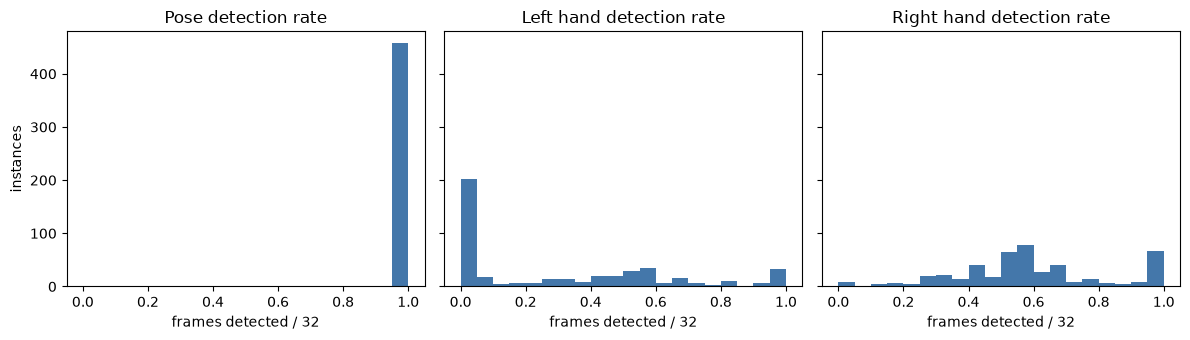

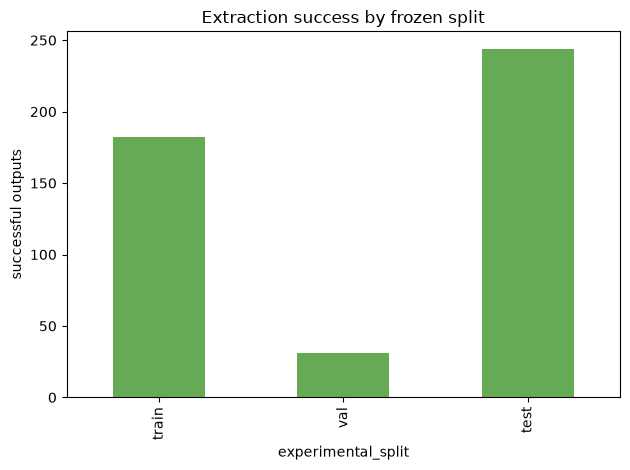

In [85]:
if not manifest.empty:
    finished = manifest.loc[manifest.status.isin(['processed','skipped_existing_valid'])]
    if not finished.empty:
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
        for ax, column, title in zip(axes, ['pose_detected_rate','left_hand_detected_rate','right_hand_detected_rate'], ['Pose','Left hand','Right hand']):
            ax.hist(finished[column], bins=np.linspace(0,1,21), color='#4477AA'); ax.set_title(f'{title} detection rate'); ax.set_xlabel('frames detected / 32')
        axes[0].set_ylabel('instances'); plt.tight_layout(); plt.savefig(QC_DIR / 'detection_rate_distribution.png', dpi=160, bbox_inches='tight'); plt.show()
        split_counts = finished.groupby('experimental_split').size().reindex(['train','val','test'], fill_value=0)
        split_counts.plot(kind='bar', color='#66AA55', ylabel='successful outputs', title='Extraction success by frozen split')
        plt.tight_layout(); plt.savefig(QC_DIR / 'extraction_success_by_split.png', dpi=160, bbox_inches='tight'); plt.show()

## 10. Landmark visualizations

One representative usable sequence is reprocessed only for an overlay visualization. A second panel, when available, shows an output frame where neither hand was detected. These plots are quality checks, not new stored data.

I0000 00:00:1793787198.701079 1086912 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M4
I0000 00:00:1793787198.704229 1086912 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M4
W0000 00:00:1793787198.707741 1116391 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787198.710133 1116391 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787198.744377 1116376 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793787198.750730 1116376 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


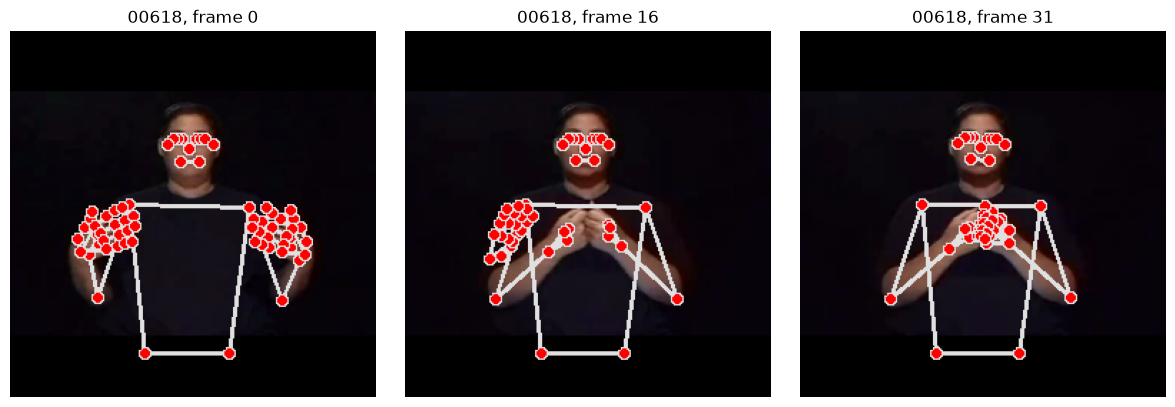

In [86]:
def draw_overlay(frame, pose, hands):
    image = cv2.cvtColor(frame.copy(), cv2.COLOR_RGB2BGR)
    pr, hr = pose.process(frame), hands.process(frame)
    draw = mp.solutions.drawing_utils
    if pr.pose_landmarks: draw.draw_landmarks(image, pr.pose_landmarks, mp.solutions.pose.POSE_CONNECTIONS)
    if hr.multi_hand_landmarks:
        for hand in hr.multi_hand_landmarks: draw.draw_landmarks(image, hand, mp.solutions.hands.HAND_CONNECTIONS)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

finished = manifest.loc[manifest.status.isin(['processed','skipped_existing_valid'])] if not manifest.empty else pd.DataFrame()
if not finished.empty:
    example = finished.iloc[0]; frames = load_frames(example.input_path)
    pose, hands = make_solutions()
    try:
        indices = [0, TARGET_FRAMES//2, TARGET_FRAMES-1]
        fig, axes = plt.subplots(1, 3, figsize=(12,4))
        for ax, i in zip(axes, indices): ax.imshow(draw_overlay(frames[i], pose, hands)); ax.set_title(f'{example.video_id}, frame {i}'); ax.axis('off')
        plt.tight_layout(); plt.savefig(QC_DIR / 'representative_landmark_overlay.png', dpi=160, bbox_inches='tight'); plt.show()
    finally: pose.close(); hands.close()
    missing = finished.loc[(finished.left_hand_detected_rate < 1) | (finished.right_hand_detected_rate < 1)]
    if not missing.empty:
        candidate = missing.iloc[0]
        with np.load(candidate.landmark_path, allow_pickle=False) as z: absent = np.flatnonzero(~z['left_hand_detected'] & ~z['right_hand_detected'])
        if len(absent):
            plt.figure(figsize=(3,3)); plt.imshow(load_frames(candidate.input_path)[absent[0]]); plt.title(f'Missing-hands example: {candidate.video_id}, frame {absent[0]}'); plt.axis('off'); plt.show()
else: print('No successful output is available for visualizations.')

## 11. Output validation

Every successful output is reopened, checked against its manifest identity and expected temporal shapes, and checked for infinite values. `NaN` is permitted only as the declared missing-detection representation.

In [87]:
validation_errors = []
for row in manifest.loc[manifest.status.isin(['processed','skipped_existing_valid'])].itertuples(index=False):
    try:
        if not output_valid(Path(row.landmark_path), row.video_id): raise ValueError('invalid output contract')
        with np.load(row.landmark_path, allow_pickle=False) as z:
            for key, mask in [('pose','pose_detected'), ('left_hand','left_hand_detected'), ('right_hand','right_hand_detected')]:
                values, detected = z[key], z[mask]
                if np.isinf(values).any(): raise ValueError(f'infinite values in {key}')
                if detected.any() and not np.isfinite(values[detected]).all(): raise ValueError(f'non-finite detected {key} values')
    except Exception as exc: validation_errors.append({'video_id': row.video_id, 'validation_error': str(exc)})
print(f'Validated {int(manifest.status.isin(["processed","skipped_existing_valid"]).sum())} outputs; validation errors: {len(validation_errors)}')
display(pd.DataFrame(validation_errors))

Validated 457 outputs; validation errors: 0


""


## 12. Final summary and next steps

Notebook 05 should consume only successful rows from `landmark_manifest.csv`, retain the masks alongside coordinates, and make any quality-filtering decision using training data only. The landmark representation is normalized image-space output from MediaPipe—not person-scale or anatomical normalization. Missing videos and low-detection outputs remain explicitly traceable.

In [88]:
successful = manifest.loc[manifest.status.isin(['processed','skipped_existing_valid'])] if not manifest.empty else manifest
summary = {'extraction_configuration': EXTRACTION_CONFIG, 'debug_mode': DEBUG_MODE, 'eligible_input_sequences': int(len(eligible)),
    'attempted_sequences': int(len(manifest)), 'successful_sequences': int(len(successful)), 'failed_sequences': int((manifest.status == 'failed').sum()) if not manifest.empty else 0,
    'validation_errors': int(len(validation_errors)), 'overall_detection_rates': ({k: float(successful[k].mean()) for k in ['pose_detected_rate','left_hand_detected_rate','right_hand_detected_rate']} if len(successful) else {}),
    'by_split': (successful.groupby('experimental_split')[['pose_detected_rate','left_hand_detected_rate','right_hand_detected_rate']].mean().reset_index().to_dict('records') if len(successful) else [])}
with open(SUMMARY_PATH, 'w', encoding='utf-8') as f: json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2)); print(f'Saved summary: {SUMMARY_PATH}')

{
  "extraction_configuration": {
    "target_frames": 32,
    "frame_shape_hwc": [
      256,
      256,
      3
    ],
    "input_color_order": "RGB",
    "pose_model_complexity": 1,
    "min_detection_confidence": 0.5,
    "min_tracking_confidence": 0.5,
    "mediapipe_version": "0.10.21",
    "missing_representation": "NaN coordinates plus Boolean per-frame detection mask",
    "handedness_convention": "subject anatomical left/right; swapped from raw MediaPipe selfie labels for unmirrored frames"
  },
  "debug_mode": false,
  "eligible_input_sequences": 457,
  "attempted_sequences": 457,
  "successful_sequences": 457,
  "failed_sequences": 0,
  "validation_errors": 0,
  "overall_detection_rates": {
    "pose_detected_rate": 0.9969228665207878,
    "left_hand_detected_rate": 0.2991657549234136,
    "right_hand_detected_rate": 0.5873222100656456
  },
  "by_split": [
    {
      "experimental_split": "test",
      "pose_detected_rate": 1.0,
      "left_hand_detected_rate": 0.250768442